In [2]:

# Step 9.4 — Download Higgs Twitter retweet network

from pathlib import Path
import urllib.request
import time

DATA = Path("/content/higgs_twitter")
DATA.mkdir(parents=True, exist_ok=True)

url = (
    "https://snap.stanford.edu/data/"
    "higgs-retweet_network.edgelist.gz"
)

destination = DATA / "higgs-retweet_network.edgelist.gz"

print("HIGGS TWITTER — RETWEET NETWORK DOWNLOAD")
print("-" * 55)

if destination.exists() and destination.stat().st_size > 0:
    print("File already exists.")
else:
    print("Downloading from Stanford SNAP...")
    start = time.time()
    urllib.request.urlretrieve(url, destination)
    print(f"Download time: {time.time() - start:.2f} seconds")

print("Filename:", destination.name)
print(f"Compressed size: {destination.stat().st_size / 1024**2:.2f} MB")
print("Download complete.")


HIGGS TWITTER — RETWEET NETWORK DOWNLOAD
-------------------------------------------------------
Download time: 0.67 seconds
Filename: higgs-retweet_network.edgelist.gz
Compressed size: 1.87 MB
Download complete.


In [3]:

# Step 9.5 — Inspect Higgs Twitter retweet network

import gzip
import time
from collections import Counter

file_path = DATA / "higgs-retweet_network.edgelist.gz"

start = time.time()

edge_count = 0
nodes = set()
self_loops = 0
sample_rows = []
invalid_rows = 0

in_degree = Counter()
out_degree = Counter()

with gzip.open(file_path, "rt") as f:
    for line in f:
        parts = line.strip().split()

        if len(parts) != 2:
            invalid_rows += 1
            continue

        source, target = map(int, parts)

        if len(sample_rows) < 5:
            sample_rows.append((source, target))

        edge_count += 1
        nodes.add(source)
        nodes.add(target)

        out_degree[source] += 1
        in_degree[target] += 1

        if source == target:
            self_loops += 1

print("HIGGS TWITTER — RETWEET NETWORK INSPECTION")
print("-" * 60)

print(f"Total edge records: {edge_count:,}")
print(f"Unique users:       {len(nodes):,}")
print(f"Self-loops:         {self_loops:,}")
print(f"Invalid rows:       {invalid_rows:,}")

print("\nFIRST FIVE EDGES")
for source, target in sample_rows:
    print(f"{source} -> {target}")

print("\nTOP FIVE USERS BY IN-DEGREE")
for node, degree in in_degree.most_common(5):
    print(f"User {node}: {degree:,}")

print("\nTOP FIVE USERS BY OUT-DEGREE")
for node, degree in out_degree.most_common(5):
    print(f"User {node}: {degree:,}")

print(f"\nProcessing time: {time.time() - start:.2f} seconds")


HIGGS TWITTER — RETWEET NETWORK INSPECTION
------------------------------------------------------------
Total edge records: 0
Unique users:       0
Self-loops:         0
Invalid rows:       328,132

FIRST FIVE EDGES

TOP FIVE USERS BY IN-DEGREE

TOP FIVE USERS BY OUT-DEGREE

Processing time: 0.31 seconds


In [4]:

# Step 9.5B — Corrected Higgs retweet network inspection

import gzip
import time
from collections import Counter

start = time.time()

edge_count = 0
nodes = set()
self_loops = 0
invalid_rows = 0

in_degree = Counter()
out_degree = Counter()
weight_counts = Counter()
edge_pairs = set()

duplicate_pairs = 0
sample_rows = []

with gzip.open(file_path, "rt") as f:
    for line in f:
        parts = line.strip().split()

        if len(parts) != 3:
            invalid_rows += 1
            continue

        source, target, weight = map(int, parts)

        if len(sample_rows) < 5:
            sample_rows.append((source, target, weight))

        edge_count += 1
        nodes.update([source, target])

        in_degree[target] += 1
        out_degree[source] += 1
        weight_counts[weight] += 1

        if source == target:
            self_loops += 1

        pair = (source, target)

        if pair in edge_pairs:
            duplicate_pairs += 1
        else:
            edge_pairs.add(pair)

print("HIGGS TWITTER — CORRECTED RETWEET INSPECTION")
print("-" * 60)

print(f"Total edge records:  {edge_count:,}")
print(f"Unique users:        {len(nodes):,}")
print(f"Unique directed edges: {len(edge_pairs):,}")
print(f"Duplicate pairs:     {duplicate_pairs:,}")
print(f"Self-loops:          {self_loops:,}")
print(f"Invalid rows:        {invalid_rows:,}")

print("\nFIRST FIVE EDGES")
for row in sample_rows:
    print(row)

print("\nEDGE WEIGHTS")
for weight, count in weight_counts.most_common(10):
    print(f"Weight {weight}: {count:,} records")

print("\nTOP FIVE USERS BY IN-DEGREE")
for node, degree in in_degree.most_common(5):
    print(f"User {node}: {degree:,}")

print("\nTOP FIVE USERS BY OUT-DEGREE")
for node, degree in out_degree.most_common(5):
    print(f"User {node}: {degree:,}")

print(f"\nProcessing time: {time.time() - start:.2f} seconds")


HIGGS TWITTER — CORRECTED RETWEET INSPECTION
------------------------------------------------------------
Total edge records:  328,132
Unique users:        256,491
Unique directed edges: 328,132
Duplicate pairs:     0
Self-loops:          0
Invalid rows:        0

FIRST FIVE EDGES
(298960, 105232, 1)
(95688, 3393, 1)
(353237, 62217, 1)
(4974, 3571, 1)
(241892, 8, 1)

EDGE WEIGHTS
Weight 1: 311,214 records
Weight 2: 12,347 records
Weight 3: 2,555 records
Weight 4: 952 records
Weight 5: 433 records
Weight 6: 218 records
Weight 7: 133 records
Weight 8: 79 records
Weight 9: 58 records
Weight 10: 35 records

TOP FIVE USERS BY IN-DEGREE
User 88: 14,060
User 14454: 6,190
User 677: 5,613
User 1988: 4,335
User 349: 2,802

TOP FIVE USERS BY OUT-DEGREE
User 38535: 134
User 181190: 84
User 81405: 66
User 64911: 49
User 54301: 49

Processing time: 1.89 seconds


In [5]:

# Step 9.6 — Construct the Higgs Twitter retweet graph

import networkx as nx
import gzip
import psutil
import os
import time

process = psutil.Process(os.getpid())

def memory_gb():
    return process.memory_info().rss / (1024 ** 3)

start = time.time()
memory_before = memory_gb()

print("BUILDING HIGGS RETWEET GRAPH")
print("-" * 60)
print(f"Process RAM before: {memory_before:.2f} GB")

G_retweet = nx.DiGraph()

with gzip.open(file_path, "rt") as f:
    for line in f:
        source, target, weight = map(int, line.split())
        G_retweet.add_edge(
            source,
            target,
            weight=weight
        )

memory_after = memory_gb()

print("\nGRAPH SUMMARY")
print("-" * 60)
print(f"Nodes: {G_retweet.number_of_nodes():,}")
print(f"Edges: {G_retweet.number_of_edges():,}")
print(f"Directed: {G_retweet.is_directed()}")
print(f"Self-loops: {nx.number_of_selfloops(G_retweet):,}")

print("\nMEMORY USAGE")
print("-" * 60)
print(f"Process RAM before: {memory_before:.2f} GB")
print(f"Process RAM after:  {memory_after:.2f} GB")
print(f"Increase:           {memory_after - memory_before:.2f} GB")
print(f"Available system RAM: {psutil.virtual_memory().available / (1024**3):.2f} GB")

print(f"\nGraph construction time: {time.time() - start:.2f} seconds")


BUILDING HIGGS RETWEET GRAPH
------------------------------------------------------------
Process RAM before: 0.19 GB

GRAPH SUMMARY
------------------------------------------------------------
Nodes: 256,491
Edges: 328,132
Directed: True
Self-loops: 0

MEMORY USAGE
------------------------------------------------------------
Process RAM before: 0.19 GB
Process RAM after:  0.39 GB
Increase:           0.20 GB
Available system RAM: 11.20 GB

Graph construction time: 2.56 seconds


In [6]:

# Step 9.7 — Higgs retweet network connectivity

import networkx as nx
import time
from collections import Counter

start = time.time()

print("HIGGS RETWEET NETWORK — CONNECTIVITY ANALYSIS")
print("-" * 60)

# Weakly connected components
weak_sizes = sorted(
    (len(component) for component in nx.weakly_connected_components(G_retweet)),
    reverse=True
)

# Strongly connected components
strong_sizes = sorted(
    (len(component) for component in nx.strongly_connected_components(G_retweet)),
    reverse=True
)

# Degree distribution
degree_counts = Counter(dict(G_retweet.degree()).values())

print(f"Total nodes: {G_retweet.number_of_nodes():,}")
print(f"Total edges: {G_retweet.number_of_edges():,}")

print("\nWEAKLY CONNECTED COMPONENTS")
print(f"Number of components: {len(weak_sizes):,}")
print(f"Largest component: {weak_sizes[0]:,} nodes")
print(f"Largest component coverage: {weak_sizes[0] / G_retweet.number_of_nodes() * 100:.2f}%")
print(f"Top 10 component sizes: {weak_sizes[:10]}")

print("\nSTRONGLY CONNECTED COMPONENTS")
print(f"Number of components: {len(strong_sizes):,}")
print(f"Largest component: {strong_sizes[0]:,} nodes")
print(f"Largest component coverage: {strong_sizes[0] / G_retweet.number_of_nodes() * 100:.2f}%")
print(f"Top 10 component sizes: {strong_sizes[:10]}")

print("\nDEGREE DISTRIBUTION")
print(f"Nodes with degree 0: {degree_counts[0]:,}")
print(f"Nodes with degree 1: {degree_counts[1]:,}")
print(f"Nodes with degree 2: {degree_counts[2]:,}")
print(f"Nodes with degree 3: {degree_counts[3]:,}")
print(f"Maximum total degree: {max(dict(G_retweet.degree()).values()):,}")

print(f"\nProcessing time: {time.time() - start:.2f} seconds")


HIGGS RETWEET NETWORK — CONNECTIVITY ANALYSIS
------------------------------------------------------------
Total nodes: 256,491
Total edges: 328,132

WEAKLY CONNECTED COMPONENTS
Number of components: 13,199
Largest component: 223,833 nodes
Largest component coverage: 87.27%
Top 10 component sizes: [223833, 69, 49, 29, 28, 25, 25, 25, 24, 22]

STRONGLY CONNECTED COMPONENTS
Number of components: 255,002
Largest component: 984 nodes
Largest component coverage: 0.38%
Top 10 component sizes: [984, 32, 17, 14, 11, 8, 7, 6, 5, 5]

DEGREE DISTRIBUTION
Nodes with degree 0: 0
Nodes with degree 1: 188,289
Nodes with degree 2: 36,107
Nodes with degree 3: 12,690
Maximum total degree: 14,063

Processing time: 1.72 seconds


In [8]:

# Step 9.9 — Higgs Twitter degree analysis

import pandas as pd
import numpy as np
import time

start = time.time()

degree_df = pd.DataFrame([
    {
        "user_id": node,
        "in_degree": G_retweet.in_degree(node),
        "out_degree": G_retweet.out_degree(node),
        "total_degree": G_retweet.degree(node)
    }
    for node in G_retweet.nodes()
])

print("HIGGS TWITTER — DEGREE ANALYSIS")
print("-" * 60)

print("\nDEGREE SUMMARY")
print(
    degree_df[
        ["in_degree", "out_degree", "total_degree"]
    ].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(2)
)

print("\nTOP 10 USERS BY IN-DEGREE")
print(
    degree_df.nlargest(10, "in_degree")[
        ["user_id", "in_degree", "out_degree", "total_degree"]
    ].to_string(index=False)
)

print("\nTOP 10 USERS BY OUT-DEGREE")
print(
    degree_df.nlargest(10, "out_degree")[
        ["user_id", "in_degree", "out_degree", "total_degree"]
    ].to_string(index=False)
)

print("\nTOP 10 USERS BY TOTAL DEGREE")
print(
    degree_df.nlargest(10, "total_degree")[
        ["user_id", "in_degree", "out_degree", "total_degree"]
    ].to_string(index=False)
)

print(f"\nProcessing time: {time.time() - start:.2f} seconds")


HIGGS TWITTER — DEGREE ANALYSIS
------------------------------------------------------------

DEGREE SUMMARY
       in_degree  out_degree  total_degree
count  256491.00   256491.00     256491.00
mean        1.28        1.28          2.56
std        38.92        1.37         38.96
min         0.00        0.00          1.00
50%         0.00        1.00          1.00
90%         1.00        2.00          3.00
95%         2.00        3.00          5.00
99%        13.00        6.00         17.00
max     14060.00      134.00      14063.00

TOP 10 USERS BY IN-DEGREE
 user_id  in_degree  out_degree  total_degree
      88      14060           3         14063
   14454       6190           0          6190
     677       5613           8          5621
    1988       4335           2          4337
     349       2802           1          2803
     283       2039           0          2039
    3571       1980           1          1981
    6948       1959           0          1959
   14572       1692 

In [9]:

# Step 9.10 — Verify Higgs Twitter edge direction

import requests
from bs4 import BeautifulSoup

url = "https://snap.stanford.edu/data/higgs-twitter.html"

response = requests.get(url, timeout=30)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")
page_text = soup.get_text(" ", strip=True)

keywords = [
    "retweet",
    "direction",
    "edge",
    "weight"
]

print("HIGGS TWITTER — DATASET DOCUMENTATION")
print("-" * 60)

for keyword in keywords:
    print(f"\nKEYWORD: {keyword.upper()}")

    start = 0
    matches = 0

    while matches < 4:
        position = page_text.lower().find(keyword, start)

        if position == -1:
            break

        left = max(0, position - 150)
        right = min(len(page_text), position + 250)

        print("\n...", page_text[left:right], "...")

        start = position + len(keyword)
        matches += 1


HIGGS TWITTER — DATASET DOCUMENTATION
------------------------------------------------------------

KEYWORD: RETWEET

...  7th July 2012 are considered. The four directional networks made available here have been extracted from user activities in Twitter as: re-tweeting (retweet network) replying (reply network) to existing tweets mentioning (mention network) other users friends/followers social relationships among user involved in the above activities information about activity on Twitter during the discovery of Hig ...

... ent 0.1887 Number of triangles 83023401 Fraction of closed triangles 0.002901 Diameter (longest shortest path) 9 90-percentile effective diameter 3.7 Retweet Network statistics Nodes 256491 Edges 328132 Nodes in largest WCC 223833 (0.873) Edges in largest WCC 308596 (0.940) Nodes in largest SCC 984 (0.004) Edges in largest SCC 3850 (0.012) Average clustering coefficient 0.0156 Number of triangles  ...

... shortest path) 18 90-percentile effective diameter 6.5 Dat

In [10]:

# Step 9.11 — Build information-flow graph

import networkx as nx
import time

start = time.time()

# Reverse retweet direction for potential information flow
G_diffusion = G_retweet.reverse(copy=True)

# Validate graph structure
assert G_diffusion.number_of_nodes() == G_retweet.number_of_nodes()
assert G_diffusion.number_of_edges() == G_retweet.number_of_edges()

# Validate a known edge from our dataset
assert G_retweet.has_edge(298960, 105232)
assert G_diffusion.has_edge(105232, 298960)

# Check that edge weights are preserved
assert (
    G_retweet[298960][105232]["weight"]
    == G_diffusion[105232][298960]["weight"]
)

print("HIGGS TWITTER — INFORMATION-FLOW GRAPH")
print("-" * 60)

print(f"Nodes: {G_diffusion.number_of_nodes():,}")
print(f"Edges: {G_diffusion.number_of_edges():,}")

print("\nEDGE-DIRECTION CHECK")
print("Observed retweet: 298960 -> 105232")
print("Potential information flow: 105232 -> 298960")

print("\nUSER 88")
print(f"Observed retweet in-degree: {G_retweet.in_degree(88):,}")
print(f"Information-flow out-degree: {G_diffusion.out_degree(88):,}")

print(f"\nConstruction time: {time.time() - start:.2f} seconds")
print("Validation successful.")


HIGGS TWITTER — INFORMATION-FLOW GRAPH
------------------------------------------------------------
Nodes: 256,491
Edges: 328,132

EDGE-DIRECTION CHECK
Observed retweet: 298960 -> 105232
Potential information flow: 105232 -> 298960

USER 88
Observed retweet in-degree: 14,060
Information-flow out-degree: 14,060

Construction time: 4.76 seconds
Validation successful.


In [11]:

# Step 9.12 — PageRank analysis of Higgs Twitter users

import networkx as nx
import pandas as pd
import time

start = time.time()

# Original retweet direction:
# A -> B means A retweeted B.
pagerank_scores = nx.pagerank(
    G_retweet,
    alpha=0.85,
    weight="weight",
    max_iter=200,
    tol=1e-6
)

# Add PageRank scores to existing degree results
degree_df["pagerank"] = (
    degree_df["user_id"].map(pagerank_scores)
)

top_pagerank = degree_df.nlargest(10, "pagerank")[
    ["user_id", "in_degree", "out_degree",
     "total_degree", "pagerank"]
]

top_in_degree = set(
    degree_df.nlargest(10, "in_degree")["user_id"]
)

top_pagerank_ids = set(top_pagerank["user_id"])

overlap = len(top_in_degree & top_pagerank_ids)

print("HIGGS TWITTER — PAGERANK ANALYSIS")
print("-" * 65)

print("\nTOP 10 USERS BY PAGERANK")
print(top_pagerank.to_string(index=False))

print("\nRANKING AGREEMENT")
print(f"Top-10 overlap with retweet in-degree: {overlap}/10")

print("\nPAGERANK SUMMARY")
print(degree_df["pagerank"].describe().to_string())

print(f"\nProcessing time: {time.time() - start:.2f} seconds")


HIGGS TWITTER — PAGERANK ANALYSIS
-----------------------------------------------------------------

TOP 10 USERS BY PAGERANK
 user_id  in_degree  out_degree  total_degree  pagerank
      88      14060           3         14063  0.028944
    2342       1022           2          1024  0.011784
   64911        192          49           241  0.008695
   14454       6190           0          6190  0.007764
   39420        168           2           170  0.007636
    1988       4335           2          4337  0.007402
     677       5613           8          5621  0.007376
    3998        833           7           840  0.007325
  134095         35           1            36  0.005739
  169287          5           5            10  0.005712

RANKING AGREEMENT
Top-10 overlap with retweet in-degree: 4/10

PAGERANK SUMMARY
count    256491.000000
mean          0.000004
std           0.000083
min           0.000002
25%           0.000002
50%           0.000002
75%           0.000002
max           0.

In [12]:

# Step 9.13 — Prepare influential-user network subgraph

import networkx as nx
import numpy as np
import time

start = time.time()

rng = np.random.default_rng(42)

top_users = degree_df.nlargest(
    20, "in_degree"
)["user_id"].tolist()

selected_nodes = set(top_users)

for user in top_users:
    # Users who retweeted this account
    neighbours = list(G_retweet.predecessors(user))

    if len(neighbours) > 15:
        neighbours = rng.choice(
            neighbours,
            size=15,
            replace=False
        ).tolist()

    selected_nodes.update(neighbours)

G_visual = G_retweet.subgraph(selected_nodes).copy()

print("HIGGS TWITTER — VISUALISATION SUBGRAPH")
print("-" * 60)

print(f"Selected influential users: {len(top_users)}")
print(f"Total nodes: {G_visual.number_of_nodes():,}")
print(f"Total edges: {G_visual.number_of_edges():,}")
print(f"Connected components (undirected): "
      f"{nx.number_connected_components(G_visual.to_undirected()):,}")

print("\nTOP USERS INCLUDED")
print(top_users[:10])

print(f"\nPreparation time: {time.time() - start:.2f} seconds")


HIGGS TWITTER — VISUALISATION SUBGRAPH
------------------------------------------------------------
Selected influential users: 20
Total nodes: 320
Total edges: 426
Connected components (undirected): 2

TOP USERS INCLUDED
[88, 14454, 677, 1988, 349, 283, 3571, 6948, 14572, 68278]

Preparation time: 0.03 seconds


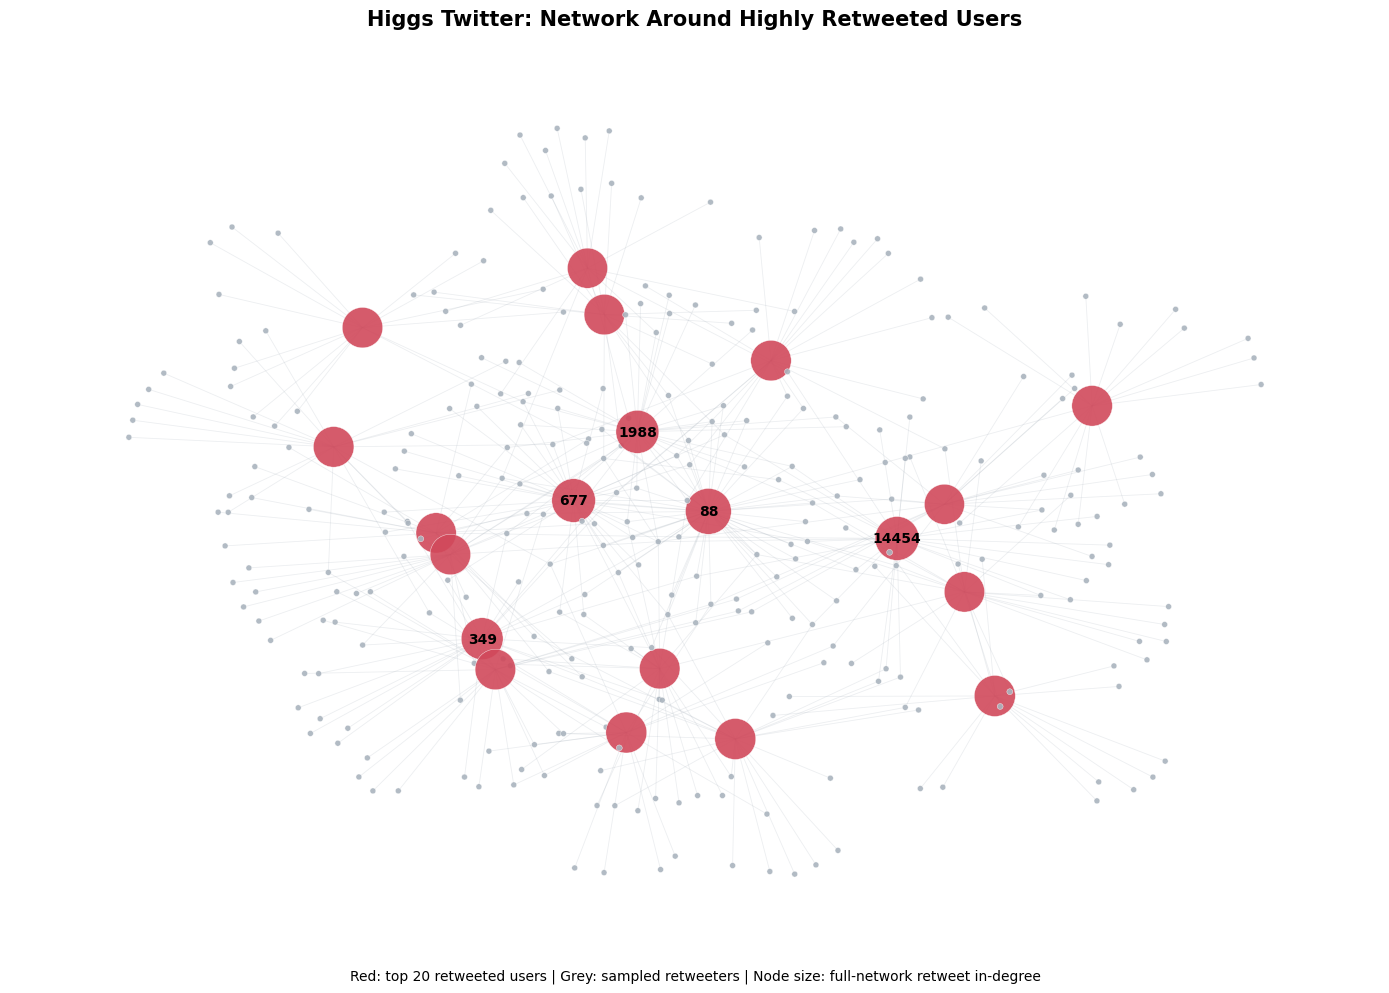

HIGGS TWITTER — INFLUENTIAL USER VISUALISATION
------------------------------------------------------------
Figure saved: /content/higgs_twitter_influential_users.png
Processing time: 2.33 seconds


In [13]:

# Step 9.14 — Visualise influential Twitter users

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import time

start = time.time()

# Reproducible layout
pos = nx.spring_layout(
    G_visual.to_undirected(),
    seed=42,
    k=0.35,
    iterations=100
)

top_user_set = set(top_users)

node_colours = [
    "#D1495B" if node in top_user_set else "#AAB4BE"
    for node in G_visual.nodes()
]

# Log scaling prevents User 88 from dominating the figure
node_sizes = [
    35 + 110 * np.log1p(G_retweet.in_degree(node))
    if node in top_user_set else 18
    for node in G_visual.nodes()
]

fig, ax = plt.subplots(figsize=(14, 10))

nx.draw_networkx_edges(
    G_visual,
    pos,
    ax=ax,
    edge_color="#AAB4BE",
    alpha=0.22,
    width=0.6,
    arrows=False
)

nx.draw_networkx_nodes(
    G_visual,
    pos,
    ax=ax,
    node_color=node_colours,
    node_size=node_sizes,
    alpha=0.9,
    linewidths=0.3,
    edgecolors="white"
)

# Label the five most-retweeted accounts
labels = {
    user: str(user)
    for user in top_users[:5]
}

nx.draw_networkx_labels(
    G_visual,
    pos,
    labels=labels,
    font_size=10,
    font_weight="bold",
    ax=ax
)

ax.set_title(
    "Higgs Twitter: Network Around Highly Retweeted Users",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.text(
    0.5, -0.03,
    "Red: top 20 retweeted users | Grey: sampled retweeters | "
    "Node size: full-network retweet in-degree",
    transform=ax.transAxes,
    ha="center",
    fontsize=10
)

ax.axis("off")
plt.tight_layout()

figure_path = "/content/higgs_twitter_influential_users.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("HIGGS TWITTER — INFLUENTIAL USER VISUALISATION")
print("-" * 60)
print("Figure saved:", figure_path)
print(f"Processing time: {time.time() - start:.2f} seconds")


In [14]:

# Step 9.15 — Inspect largest connected component

import networkx as nx
import time

start = time.time()

# Community detection generally uses undirected connectivity
G_undirected = G_retweet.to_undirected()

largest_component_nodes = max(
    nx.connected_components(G_undirected),
    key=len
)

G_lcc = G_undirected.subgraph(
    largest_component_nodes
).copy()

print("HIGGS TWITTER — LARGEST CONNECTED COMPONENT")
print("-" * 60)

print(f"Full network nodes: {G_retweet.number_of_nodes():,}")
print(f"Full network edges: {G_retweet.number_of_edges():,}")

print(f"\nLargest component nodes: {G_lcc.number_of_nodes():,}")
print(f"Largest component edges: {G_lcc.number_of_edges():,}")

print(
    f"Node coverage: "
    f"{100 * G_lcc.number_of_nodes() / G_retweet.number_of_nodes():.2f}%"
)

print(
    f"Edge coverage: "
    f"{100 * G_lcc.number_of_edges() / G_undirected.number_of_edges():.2f}%"
)

print(f"\nProcessing time: {time.time() - start:.2f} seconds")


HIGGS TWITTER — LARGEST CONNECTED COMPONENT
------------------------------------------------------------
Full network nodes: 256,491
Full network edges: 328,132

Largest component nodes: 223,833
Largest component edges: 307,884
Node coverage: 87.27%
Edge coverage: 94.05%

Processing time: 10.24 seconds


In [15]:

# Step 9.16 — Create a 5,000-node connected Twitter sample

import networkx as nx
import numpy as np
import time

start = time.time()

SEED = 42
TARGET_NODES = 5000

rng = np.random.default_rng(SEED)

# Choose a moderate-degree starting node
candidates = sorted(
    node for node, degree in G_lcc.degree()
    if 3 <= degree <= 10
)

start_node = int(rng.choice(candidates))

# BFS produces a connected set of nodes
bfs_nodes = []

for node in nx.bfs_tree(
    G_lcc,
    source=start_node,
    sort_neighbors=sorted
):
    bfs_nodes.append(node)

    if len(bfs_nodes) >= TARGET_NODES:
        break

# Induced subgraph retains all edges among selected nodes
G_twitter_sample = G_lcc.subgraph(bfs_nodes).copy()

print("HIGGS TWITTER — CONNECTED SAMPLE")
print("-" * 60)

print(f"Random seed: {SEED}")
print(f"Starting user: {start_node}")
print(f"Sample nodes: {G_twitter_sample.number_of_nodes():,}")
print(f"Sample edges: {G_twitter_sample.number_of_edges():,}")

print(
    "Connected:",
    nx.is_connected(G_twitter_sample)
)

print(
    "Average degree:",
    round(
        sum(dict(G_twitter_sample.degree()).values())
        / G_twitter_sample.number_of_nodes(),
        2
    )
)

print(
    "Sample density:",
    round(nx.density(G_twitter_sample), 6)
)

print(f"\nProcessing time: {time.time() - start:.2f} seconds")


HIGGS TWITTER — CONNECTED SAMPLE
------------------------------------------------------------
Random seed: 42
Starting user: 15746
Sample nodes: 5,000
Sample edges: 7,914
Connected: True
Average degree: 3.17
Sample density: 0.000633

Processing time: 3.85 seconds


In [16]:

# Step 9.17 — Louvain community detection

import networkx as nx
import pandas as pd
import time

start = time.time()

louvain_communities = nx.community.louvain_communities(
    G_twitter_sample,
    seed=42,
    weight="weight"
)

louvain_modularity = nx.community.modularity(
    G_twitter_sample,
    louvain_communities,
    weight="weight"
)

louvain_sizes = sorted(
    [len(community) for community in louvain_communities],
    reverse=True
)

louvain_runtime = time.time() - start

print("HIGGS TWITTER — LOUVAIN COMMUNITY DETECTION")
print("-" * 65)

print(f"Number of communities: {len(louvain_communities)}")
print(f"Modularity: {louvain_modularity:.4f}")
print(f"Execution time: {louvain_runtime:.2f} seconds")

print("\nCOMMUNITY SIZE SUMMARY")
print(pd.Series(louvain_sizes).describe().round(2))

print("\n10 LARGEST COMMUNITIES")
for rank, size in enumerate(louvain_sizes[:10], start=1):
    print(f"{rank:2d}. {size:,} users")

print(
    "\nAll nodes assigned:",
    sum(louvain_sizes) == G_twitter_sample.number_of_nodes()
)


HIGGS TWITTER — LOUVAIN COMMUNITY DETECTION
-----------------------------------------------------------------
Number of communities: 19
Modularity: 0.6248
Execution time: 0.32 seconds

COMMUNITY SIZE SUMMARY
count      19.00
mean      263.16
std       311.13
min         4.00
25%        56.00
50%       199.00
75%       350.00
max      1179.00
dtype: float64

10 LARGEST COMMUNITIES
 1. 1,179 users
 2. 759 users
 3. 646 users
 4. 450 users
 5. 438 users
 6. 262 users
 7. 230 users
 8. 219 users
 9. 217 users
10. 199 users

All nodes assigned: True


In [17]:

# Step 9.18 — Label Propagation community detection

import networkx as nx
import pandas as pd
import time

start = time.time()

lpa_communities = list(
    nx.community.asyn_lpa_communities(
        G_twitter_sample,
        weight="weight",
        seed=42
    )
)

lpa_modularity = nx.community.modularity(
    G_twitter_sample,
    lpa_communities,
    weight="weight"
)

lpa_sizes = sorted(
    [len(community) for community in lpa_communities],
    reverse=True
)

lpa_runtime = time.time() - start

print("HIGGS TWITTER — LABEL PROPAGATION")
print("-" * 65)

print(f"Number of communities: {len(lpa_communities)}")
print(f"Modularity: {lpa_modularity:.4f}")
print(f"Execution time: {lpa_runtime:.2f} seconds")

print("\nCOMMUNITY SIZE SUMMARY")
print(pd.Series(lpa_sizes).describe().round(2))

print("\n10 LARGEST COMMUNITIES")
for rank, size in enumerate(lpa_sizes[:10], start=1):
    print(f"{rank:2d}. {size:,} users")

print(
    "\nAll nodes assigned:",
    sum(lpa_sizes) == G_twitter_sample.number_of_nodes()
)

print("\nCOMPARISON WITH LOUVAIN")
print(f"{'Metric':<24} {'Louvain':>12} {'Label Prop.':>14}")
print("-" * 52)
print(f"{'Communities':<24} {len(louvain_communities):>12} {len(lpa_communities):>14}")
print(f"{'Modularity':<24} {louvain_modularity:>12.4f} {lpa_modularity:>14.4f}")
print(f"{'Runtime (seconds)':<24} {louvain_runtime:>12.2f} {lpa_runtime:>14.2f}")


HIGGS TWITTER — LABEL PROPAGATION
-----------------------------------------------------------------
Number of communities: 210
Modularity: 0.5752
Execution time: 0.33 seconds

COMMUNITY SIZE SUMMARY
count     210.00
mean       23.81
std       116.70
min         2.00
25%         2.00
50%         3.00
75%         5.00
max      1248.00
dtype: float64

10 LARGEST COMMUNITIES
 1. 1,248 users
 2. 679 users
 3. 662 users
 4. 500 users
 5. 425 users
 6. 152 users
 7. 125 users
 8. 121 users
 9. 103 users
10. 71 users

All nodes assigned: True

COMPARISON WITH LOUVAIN
Metric                        Louvain    Label Prop.
----------------------------------------------------
Communities                        19            210
Modularity                     0.6248         0.5752
Runtime (seconds)                0.32           0.33


In [18]:

# Step 9.19 — Compare Louvain and LPA community assignments

from sklearn.metrics import (
    normalized_mutual_info_score,
    adjusted_rand_score
)
import pandas as pd
import time

start = time.time()

# Use the same node ordering for both partitions
nodes = sorted(G_twitter_sample.nodes())

def communities_to_labels(communities):
    mapping = {
        node: community_id
        for community_id, community in enumerate(communities)
        for node in community
    }
    return [mapping[node] for node in nodes]

louvain_labels = communities_to_labels(louvain_communities)
lpa_labels = communities_to_labels(lpa_communities)

nmi_score = normalized_mutual_info_score(
    louvain_labels,
    lpa_labels
)

ari_score = adjusted_rand_score(
    louvain_labels,
    lpa_labels
)

print("HIGGS TWITTER — COMMUNITY AGREEMENT")
print("-" * 60)

print(f"Louvain communities: {len(louvain_communities)}")
print(f"LPA communities: {len(lpa_communities)}")

print(f"\nNormalized Mutual Information (NMI): {nmi_score:.4f}")
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")

print(f"\nProcessing time: {time.time() - start:.2f} seconds")


HIGGS TWITTER — COMMUNITY AGREEMENT
------------------------------------------------------------
Louvain communities: 19
LPA communities: 210

Normalized Mutual Information (NMI): 0.7006
Adjusted Rand Index (ARI): 0.7879

Processing time: 0.09 seconds


In [19]:

# Step 9.20 — Stability across random seeds

import networkx as nx
import pandas as pd
from sklearn.metrics import adjusted_rand_score
import time

seeds = list(range(42, 52))
nodes = sorted(G_twitter_sample.nodes())

def partition_labels(communities):
    mapping = {
        node: i
        for i, community in enumerate(communities)
        for node in community
    }
    return [mapping[node] for node in nodes]

results = []

for algorithm in ["Louvain", "LPA"]:
    reference_labels = None

    for seed in seeds:
        start = time.time()

        if algorithm == "Louvain":
            communities = nx.community.louvain_communities(
                G_twitter_sample,
                seed=seed,
                weight="weight"
            )
        else:
            communities = list(
                nx.community.asyn_lpa_communities(
                    G_twitter_sample,
                    weight="weight",
                    seed=seed
                )
            )

        runtime = time.time() - start

        labels = partition_labels(communities)

        if reference_labels is None:
            reference_labels = labels

        results.append({
            "algorithm": algorithm,
            "seed": seed,
            "communities": len(communities),
            "modularity": nx.community.modularity(
                G_twitter_sample,
                communities,
                weight="weight"
            ),
            "ARI_vs_first": adjusted_rand_score(
                reference_labels,
                labels
            ),
            "runtime_seconds": runtime
        })

stability_df = pd.DataFrame(results)

print("HIGGS TWITTER — COMMUNITY STABILITY")
print("-" * 65)

print("\nSUMMARY ACROSS 10 RANDOM SEEDS")
print(
    stability_df.groupby("algorithm")[
        ["communities", "modularity",
         "ARI_vs_first", "runtime_seconds"]
    ].agg(["mean", "std"]).round(4).to_string()
)

print("\nINDIVIDUAL RUNS")
print(stability_df.round(4).to_string(index=False))


HIGGS TWITTER — COMMUNITY STABILITY
-----------------------------------------------------------------

SUMMARY ACROSS 10 RANDOM SEEDS
          communities          modularity         ARI_vs_first         runtime_seconds        
                 mean      std       mean     std         mean     std            mean     std
algorithm                                                                                     
LPA             197.3  21.8939     0.5826  0.0053       0.8544  0.0576          0.2671  0.0388
Louvain          17.5   1.5092     0.6269  0.0019       0.9294  0.0281          0.7073  0.4383

INDIVIDUAL RUNS
algorithm  seed  communities  modularity  ARI_vs_first  runtime_seconds
  Louvain    42           19      0.6248        1.0000           0.7959
  Louvain    43           16      0.6248        0.9327           1.7427
  Louvain    44           16      0.6290        0.9128           0.9613
  Louvain    45           18      0.6295        0.9067           0.9372
  Louvain    4

In [20]:

# Step 9.21 — Spectral Clustering feasibility check

import psutil
import numpy as np

n = G_twitter_sample.number_of_nodes()
m = G_twitter_sample.number_of_edges()

available_gb = psutil.virtual_memory().available / (1024**3)

# Memory needed for one dense n x n float64 matrix
dense_matrix_gb = (n * n * 8) / (1024**3)

print("HIGGS TWITTER — SPECTRAL CLUSTERING FEASIBILITY")
print("-" * 65)

print(f"Sample nodes: {n:,}")
print(f"Sample edges: {m:,}")
print(f"Available RAM: {available_gb:.2f} GB")

print("\nDENSE MATRIX ESTIMATE")
print(f"One dense {n:,} x {n:,} matrix: {dense_matrix_gb:.2f} GB")

print("\nGRAPH CHARACTERISTICS")
print(f"Density: {nx.density(G_twitter_sample):.6f}")
print(f"Connected: {nx.is_connected(G_twitter_sample)}")

print("\nNOTE")
print("Sparse spectral methods can avoid storing a full dense matrix.")
print("Actual memory use depends on the solver and implementation.")


HIGGS TWITTER — SPECTRAL CLUSTERING FEASIBILITY
-----------------------------------------------------------------
Sample nodes: 5,000
Sample edges: 7,914
Available RAM: 10.27 GB

DENSE MATRIX ESTIMATE
One dense 5,000 x 5,000 matrix: 0.19 GB

GRAPH CHARACTERISTICS
Density: 0.000633
Connected: True

NOTE
Sparse spectral methods can avoid storing a full dense matrix.
Actual memory use depends on the solver and implementation.


In [21]:

# Step 9.22 — Spectral Clustering on 5,000-node Twitter sample

import numpy as np
import networkx as nx
import time

from scipy.sparse import csgraph
from scipy.sparse.linalg import eigsh
from sklearn.cluster import KMeans

start = time.time()

nodes = sorted(G_twitter_sample.nodes())
n_clusters = 19

# Sparse weighted adjacency matrix
A = nx.to_scipy_sparse_array(
    G_twitter_sample,
    nodelist=nodes,
    weight="weight",
    format="csr",
    dtype=np.float64
)

# Normalised graph Laplacian
L = csgraph.laplacian(A, normed=True)

# Convert to scipy sparse matrix for eigsh compatibility
from scipy.sparse import csr_matrix
L = csr_matrix(L)

print("Computing spectral embedding...", flush=True)

# Smallest eigenvectors of normalised Laplacian
eigenvalues, eigenvectors = eigsh(
    L,
    k=n_clusters,
    which="SM",
    tol=1e-3
)

# Normalise each node's embedding
norms = np.linalg.norm(eigenvectors, axis=1, keepdims=True)
embedding = eigenvectors / np.maximum(norms, 1e-12)

print("Clustering spectral embedding...", flush=True)

spectral_labels = KMeans(
    n_clusters=n_clusters,
    random_state=42,
    n_init=10
).fit_predict(embedding)

spectral_communities = [
    set(np.array(nodes)[spectral_labels == i])
    for i in range(n_clusters)
]

spectral_modularity = nx.community.modularity(
    G_twitter_sample,
    spectral_communities,
    weight="weight"
)

spectral_runtime = time.time() - start

print("\nHIGGS TWITTER — SPECTRAL CLUSTERING")
print("-" * 65)

print(f"Nodes: {len(nodes):,}")
print(f"Communities: {len(spectral_communities)}")
print(f"Modularity: {spectral_modularity:.4f}")
print(f"Runtime: {spectral_runtime:.2f} seconds")

print("\nCOMMUNITY SIZES")
print(
    sorted(
        [len(c) for c in spectral_communities],
        reverse=True
    )[:10]
)

print("\nSMALLEST EIGENVALUES")
print(np.sort(eigenvalues)[:10].round(6))


Computing spectral embedding...
Clustering spectral embedding...

HIGGS TWITTER — SPECTRAL CLUSTERING
-----------------------------------------------------------------
Nodes: 5,000
Communities: 19
Modularity: 0.5333
Runtime: 0.68 seconds

COMMUNITY SIZES
[1164, 802, 644, 479, 442, 292, 202, 188, 183, 148]

SMALLEST EIGENVALUES
[-0.        0.037313  0.050779  0.056132  0.071042  0.077086  0.08706
  0.095444  0.107597  0.123367]


In [22]:

# Step 9.23 — Pairwise community agreement

import pandas as pd
from sklearn.metrics import (
    normalized_mutual_info_score,
    adjusted_rand_score
)

# Ensure every algorithm uses the same node ordering
nodes = sorted(G_twitter_sample.nodes())

def labels_from_communities(communities, nodes):
    mapping = {
        node: community_id
        for community_id, community in enumerate(communities)
        for node in community
    }
    return [mapping[node] for node in nodes]

partitions = {
    "Louvain": labels_from_communities(
        louvain_communities, nodes
    ),
    "LPA": labels_from_communities(
        lpa_communities, nodes
    ),
    "Spectral": labels_from_communities(
        spectral_communities, nodes
    )
}

pairs = [
    ("Louvain", "LPA"),
    ("Louvain", "Spectral"),
    ("LPA", "Spectral")
]

agreement_results = []

for algorithm_a, algorithm_b in pairs:
    labels_a = partitions[algorithm_a]
    labels_b = partitions[algorithm_b]

    agreement_results.append({
        "Comparison": f"{algorithm_a} vs {algorithm_b}",
        "NMI": normalized_mutual_info_score(
            labels_a, labels_b
        ),
        "ARI": adjusted_rand_score(
            labels_a, labels_b
        )
    })

agreement_df = pd.DataFrame(agreement_results)

print("HIGGS TWITTER — THREE-ALGORITHM AGREEMENT")
print("-" * 65)
print(agreement_df.round(4).to_string(index=False))


HIGGS TWITTER — THREE-ALGORITHM AGREEMENT
-----------------------------------------------------------------
         Comparison    NMI    ARI
     Louvain vs LPA 0.7006 0.7879
Louvain vs Spectral 0.6991 0.8306
    LPA vs Spectral 0.7042 0.8036


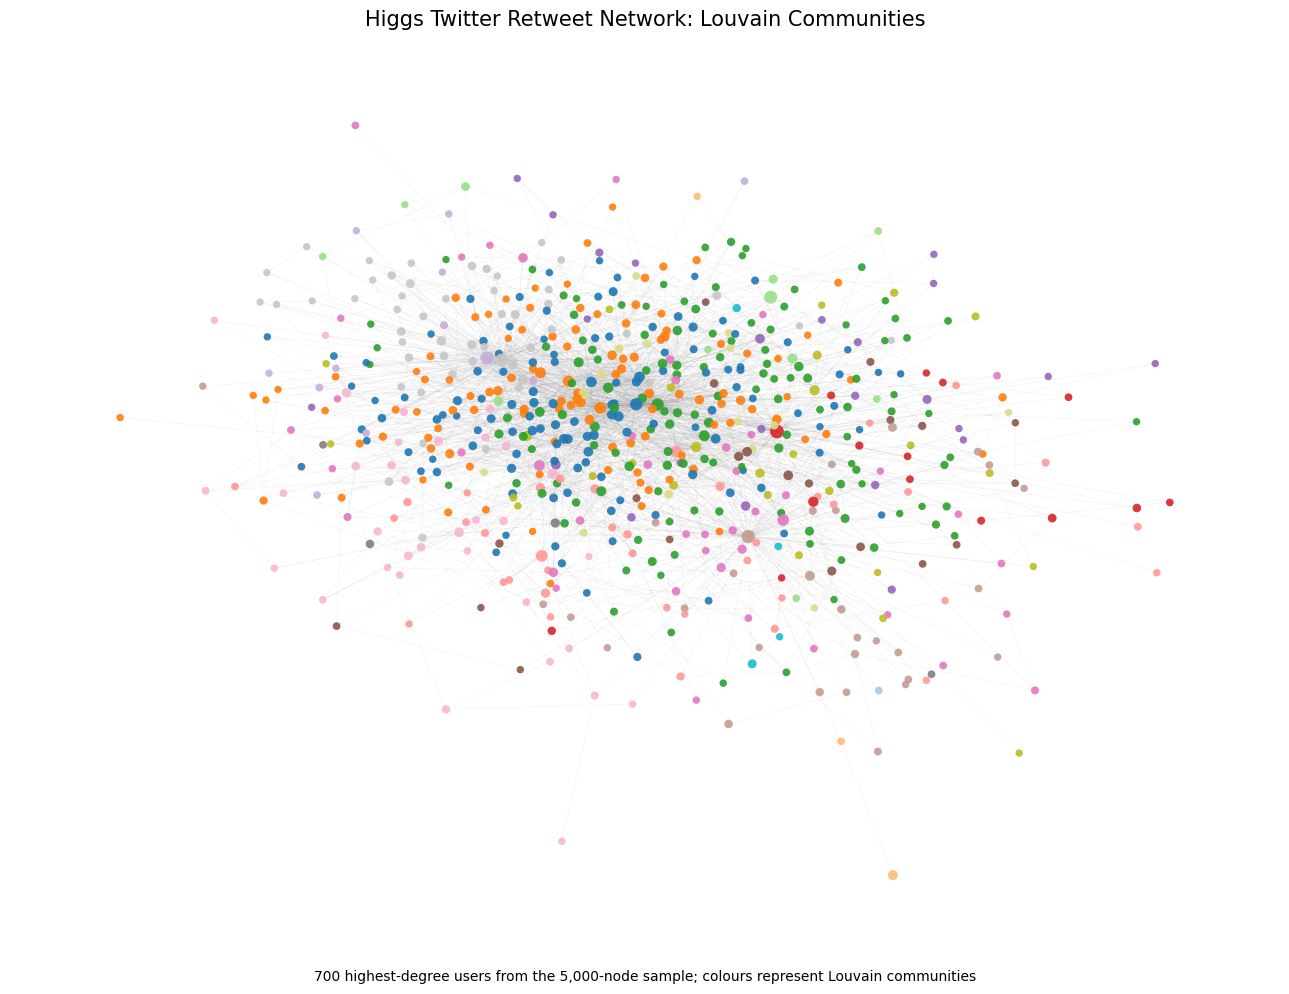

HIGGS TWITTER — COMMUNITY VISUALISATION
------------------------------------------------------------
Displayed nodes: 700
Displayed edges: 2,675
Communities represented: 19
Figure saved: /content/higgs_twitter_communities.png


In [23]:

# Step 9.24 — Community-coloured Twitter network

import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Map each user to its Louvain community
community_map = {
    node: community_id
    for community_id, community in enumerate(louvain_communities)
    for node in community
}

# Select the 700 highest-degree users for a readable figure
selected_nodes = sorted(
    G_twitter_sample.nodes(),
    key=lambda node: (
        -G_twitter_sample.degree(node),
        node
    )
)[:700]

G_plot = G_twitter_sample.subgraph(selected_nodes).copy()

# Reproducible network layout
positions = nx.spring_layout(
    G_plot,
    seed=42,
    iterations=100
)

community_ids = np.array([
    community_map[node] for node in G_plot.nodes()
])

degrees = np.array([
    G_twitter_sample.degree(node)
    for node in G_plot.nodes()
])

node_sizes = 12 + 12 * np.log1p(degrees)

fig, ax = plt.subplots(figsize=(13, 10))

nx.draw_networkx_edges(
    G_plot,
    positions,
    ax=ax,
    alpha=0.10,
    width=0.4,
    edge_color="grey"
)

nx.draw_networkx_nodes(
    G_plot,
    positions,
    ax=ax,
    node_size=node_sizes,
    node_color=community_ids,
    cmap=plt.cm.tab20,
    vmin=0,
    vmax=19,
    alpha=0.90,
    linewidths=0
)

ax.set_title(
    "Higgs Twitter Retweet Network: Louvain Communities",
    fontsize=15,
    pad=15
)

ax.text(
    0.5, -0.03,
    "700 highest-degree users from the 5,000-node sample; "
    "colours represent Louvain communities",
    transform=ax.transAxes,
    ha="center",
    fontsize=10
)

ax.axis("off")
plt.tight_layout()

figure_path = "/content/higgs_twitter_communities.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("HIGGS TWITTER — COMMUNITY VISUALISATION")
print("-" * 60)
print(f"Displayed nodes: {G_plot.number_of_nodes():,}")
print(f"Displayed edges: {G_plot.number_of_edges():,}")
print(f"Communities represented: {len(set(community_ids))}")
print(f"Figure saved: {figure_path}")


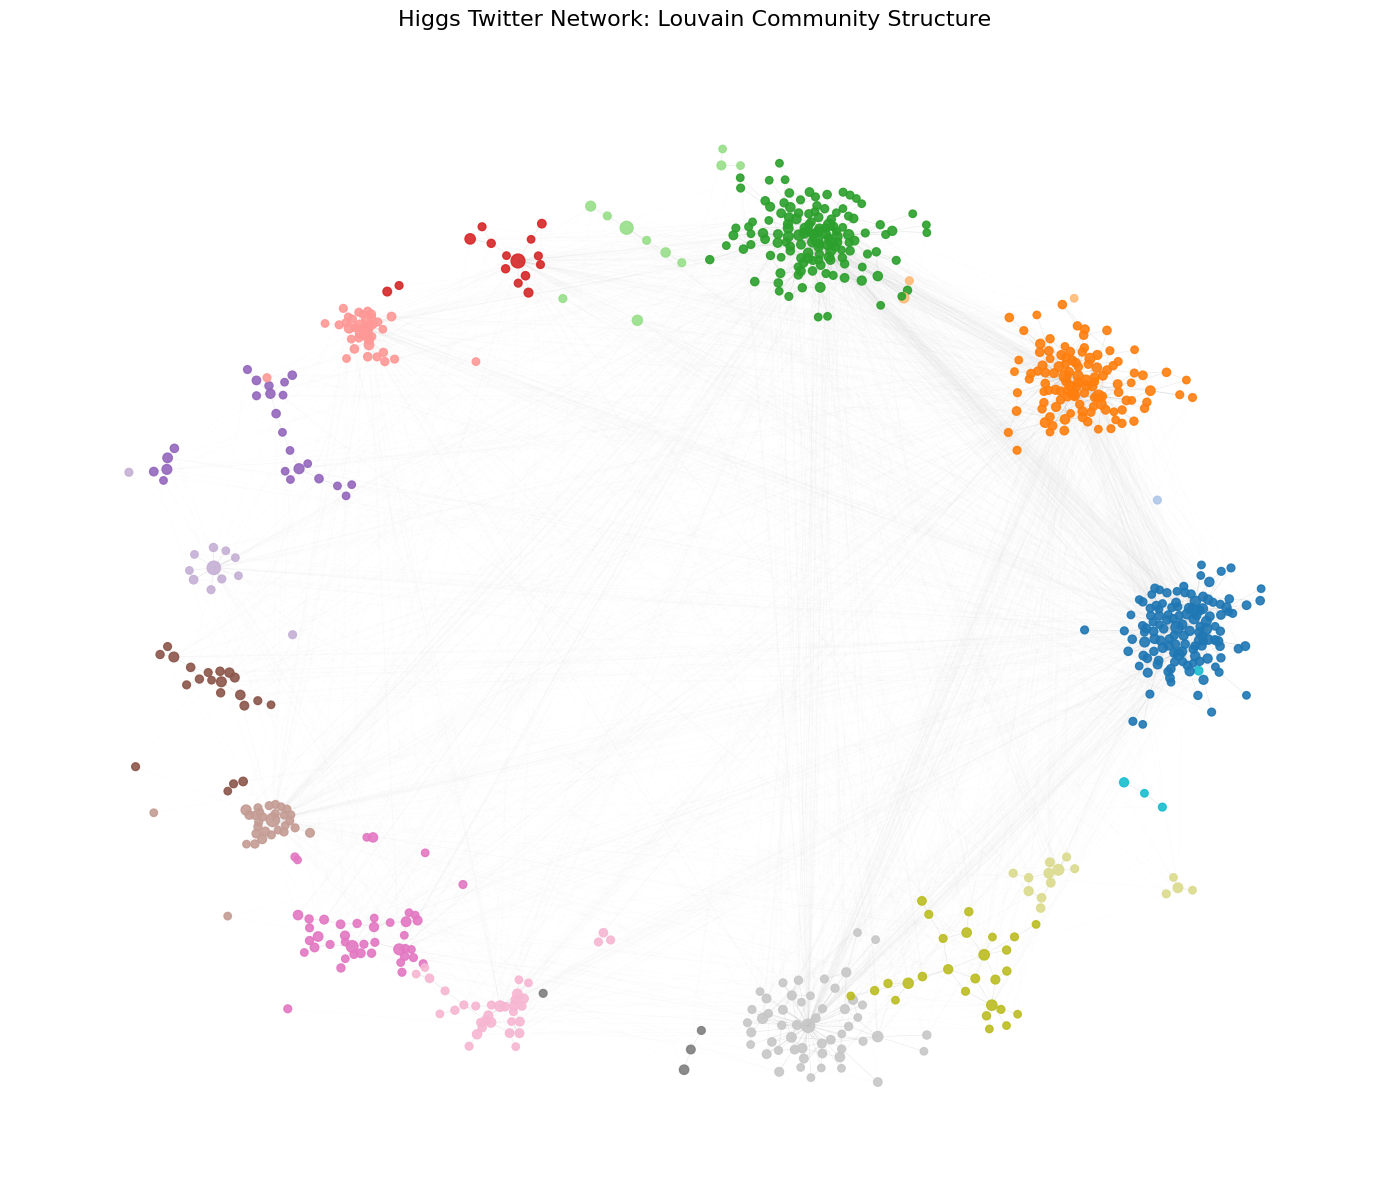

Saved: /content/higgs_twitter_community_structure.png
Communities: 19
Within-community edges: 1124
Cross-community edges: 1551


In [24]:

# Step 9.25 — Community-focused Twitter visualisation

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# Reuse the 700-node graph and Louvain community assignments
groups = sorted(set(community_map[n] for n in G_plot.nodes()))
n_groups = len(groups)

# Place communities around a circle
community_centres = {}

for i, group in enumerate(groups):
    angle = 2 * np.pi * i / n_groups
    community_centres[group] = np.array([
        3.5 * np.cos(angle),
        3.5 * np.sin(angle)
    ])

# Compute a separate layout for each community
pos = {}

for group in groups:
    group_nodes = [
        n for n in G_plot.nodes()
        if community_map[n] == group
    ]

    subgraph = G_plot.subgraph(group_nodes)

    local_pos = nx.spring_layout(
        subgraph,
        seed=42,
        scale=0.8
    )

    centre = community_centres[group]

    for node, coordinates in local_pos.items():
        pos[node] = coordinates + centre

# Colour by community
node_colours = [
    community_map[n] for n in G_plot.nodes()
]

node_sizes = [
    12 + 12 * np.log1p(G_twitter_sample.degree(n))
    for n in G_plot.nodes()
]

fig, ax = plt.subplots(figsize=(14, 12))

# Draw within-community connections more prominently
within_edges = [
    (u, v) for u, v in G_plot.edges()
    if community_map[u] == community_map[v]
]

cross_edges = [
    (u, v) for u, v in G_plot.edges()
    if community_map[u] != community_map[v]
]

nx.draw_networkx_edges(
    G_plot, pos,
    edgelist=cross_edges,
    edge_color="lightgrey",
    alpha=0.06,
    width=0.4,
    ax=ax
)

nx.draw_networkx_edges(
    G_plot, pos,
    edgelist=within_edges,
    edge_color="grey",
    alpha=0.15,
    width=0.5,
    ax=ax
)

nx.draw_networkx_nodes(
    G_plot, pos,
    node_color=node_colours,
    node_size=node_sizes,
    cmap=plt.cm.tab20,
    vmin=0,
    vmax=19,
    alpha=0.9,
    ax=ax
)

ax.set_title(
    "Higgs Twitter Network: Louvain Community Structure",
    fontsize=16,
    pad=18
)

ax.axis("off")
plt.tight_layout()

output_path = "/content/higgs_twitter_community_structure.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path)
print("Communities:", n_groups)
print("Within-community edges:", len(within_edges))
print("Cross-community edges:", len(cross_edges))


In [25]:

# Step 9.26 — Save Higgs Twitter RQ1 results

from pathlib import Path
import pandas as pd

output_dir = Path("/content/higgs_twitter/results")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Main algorithm comparison
comparison_df = pd.DataFrame([
    {
        "algorithm": "Louvain",
        "communities": len(louvain_communities),
        "modularity": louvain_modularity,
        "runtime_seconds": louvain_runtime
    },
    {
        "algorithm": "Label Propagation",
        "communities": len(lpa_communities),
        "modularity": lpa_modularity,
        "runtime_seconds": lpa_runtime
    },
    {
        "algorithm": "Spectral Clustering",
        "communities": len(spectral_communities),
        "modularity": spectral_modularity,
        "runtime_seconds": spectral_runtime
    }
])

comparison_df.to_csv(
    output_dir / "higgs_community_comparison.csv",
    index=False
)

# 2. Community agreement
agreement_df.to_csv(
    output_dir / "higgs_community_agreement.csv",
    index=False
)

# 3. Stability across random seeds
stability_df.to_csv(
    output_dir / "higgs_community_stability.csv",
    index=False
)

print("HIGGS TWITTER — RQ1 RESULTS SAVED")
print("-" * 60)

for path in sorted(output_dir.glob("higgs_community_*.csv")):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

print("\nMAIN COMPARISON")
print(comparison_df.round(4).to_string(index=False))


HIGGS TWITTER — RQ1 RESULTS SAVED
------------------------------------------------------------
higgs_community_agreement.csv: 183 bytes
higgs_community_comparison.csv: 220 bytes
higgs_community_stability.csv: 1,429 bytes

MAIN COMPARISON
          algorithm  communities  modularity  runtime_seconds
            Louvain           19      0.6248           0.3234
  Label Propagation          210      0.5752           0.3304
Spectral Clustering           19      0.5333           0.6829


In [26]:

# Step 9.27 — Package Higgs Twitter RQ1 outputs

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

base = Path("/content")
zip_path = base / "higgs_twitter_rq1_outputs.zip"

files_to_package = {
    base / "higgs_twitter/results/higgs_community_comparison.csv":
        "results/higgs_community_comparison.csv",
    base / "higgs_twitter/results/higgs_community_agreement.csv":
        "results/higgs_community_agreement.csv",
    base / "higgs_twitter/results/higgs_community_stability.csv":
        "results/higgs_community_stability.csv",
    base / "higgs_twitter_communities.png":
        "figures/higgs_twitter_communities.png",
    base / "higgs_twitter_community_structure.png":
        "figures/higgs_twitter_community_structure.png",
    base / "higgs_twitter_influential_users.png":
        "figures/higgs_twitter_influential_users.png"
}

with ZipFile(zip_path, "w", ZIP_DEFLATED) as archive:
    for source, destination in files_to_package.items():
        if source.exists():
            archive.write(source, destination)
            print(f"Added: {destination}")
        else:
            print(f"WARNING — Missing: {source}")

print(f"\nZIP created: {zip_path}")
print(f"ZIP size: {zip_path.stat().st_size / 1024**2:.2f} MB")

files.download(str(zip_path))


Added: results/higgs_community_comparison.csv
Added: results/higgs_community_agreement.csv
Added: results/higgs_community_stability.csv
Added: figures/higgs_twitter_communities.png
Added: figures/higgs_twitter_community_structure.png
Added: figures/higgs_twitter_influential_users.png

ZIP created: /content/higgs_twitter_rq1_outputs.zip
ZIP size: 6.51 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>